<a href="https://colab.research.google.com/github/muralisagili007-del/EDA-PROJECT/blob/main/random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv('/content/credit_card_fraud_detection_2026.csv')

In [ ]:
df.head()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,...,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.36,Healthcare & Pharmacy,USA,2,Monday,...,Chrome,0,93.91,39.48,0,0,corporate,0,Legitimate,0.0
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.04,Restaurant & Dining,Germany,3,Monday,...,NaN,0,180.05,134.45,0,0,yahoo,0,Legitimate,0.0
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.87,Grocery & Supermarket,Australia,3,Monday,...,Chrome,0,42.00,22.46,0,0,hotmail,0,Legitimate,0.0
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.60,Gas Station,China,3,Monday,...,NaN,0,64.87,29.76,0,0,gmail,0,Legitimate,0.0
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.13,Clothing & Apparel,UK,4,Monday,...,NaN,0,47.19,18.52,0,0,gmail,0,Legitimate,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  object 
 1   customer_id                  100000 non-null  object 
 2   card_id                      100000 non-null  object 
 3   merchant_id                  100000 non-null  object 
 4   transaction_datetime         100000 non-null  object 
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  object 
 7   merchant_country             100000 non-null  object 
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  object 
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  object 
 13  

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
transaction_amount,100000.0,126.871977,276.180425,0.500,21.2800,52.260,129.72000,15000.000
transaction_hour,100000.0,14.393860,5.018253,0.000,11.0000,14.000,19.00000,23.000
card_present,100000.0,0.357770,0.479346,0.000,0.0000,0.000,1.00000,1.000
customer_age,100000.0,42.223670,14.246361,18.000,32.0000,42.000,52.00000,85.000
account_age_days,100000.0,785.451240,747.492434,1.000,233.0000,554.000,1103.00000,3650.000
credit_limit,100000.0,10083.182000,6510.646682,500.000,5000.0000,8500.000,13650.00000,36670.000
credit_score,100000.0,682.329280,92.122179,328.000,620.0000,683.000,748.00000,850.000
num_cards_held,100000.0,2.198830,1.163491,1.000,1.0000,2.000,3.00000,5.000
transactions_last_1h,100000.0,0.783890,1.348801,0.000,0.0000,0.000,1.00000,8.000
transactions_last_24h,100000.0,2.951760,2.382417,0.000,1.0000,2.000,4.00000,18.000


In [ ]:
df.isnull().sum()

,0
transaction_id,0
customer_id,0
card_id,0
merchant_id,0
transaction_datetime,0
transaction_amount,0
merchant_category,0
merchant_country,0
transaction_hour,0
transaction_day_of_week,0


In [9]:
df.duplicated().sum()

np.int64(0)

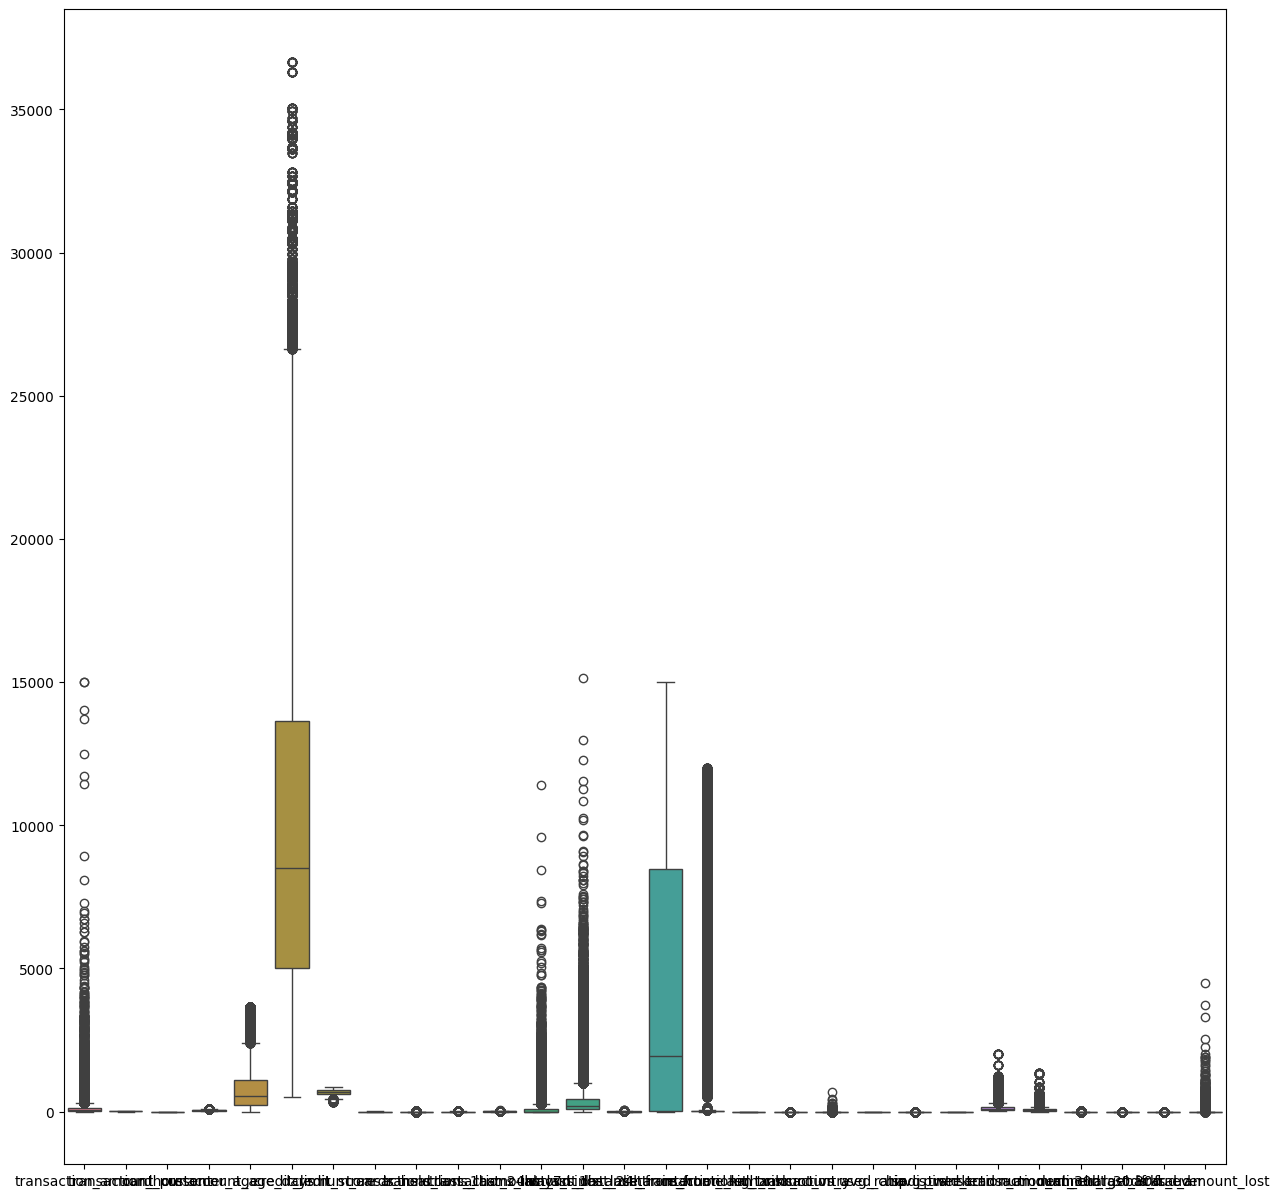

In [10]:
plt.figure(figsize=(15,15))
sns.boxplot(data = df.select_dtypes(include='number'))
plt.show()

In [12]:
# Outlier treatment
df.columns = df.columns.str.strip()

# Targeting actual numeric columns in the dataset that contain significant outliers
columns = [
    'transaction_amount',
    'distance_from_home_km'
]

for i in columns:
  Q1 = df[i].quantile(0.25)
  Q3 = df[i].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  df[i] = np.where(df[i] < lower_bound, lower_bound, df[i])
  df[i] = np.where(df[i] > upper_bound, upper_bound, df[i])

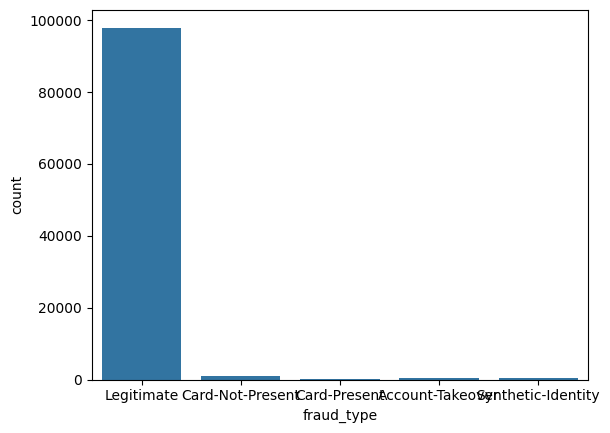

In [14]:
# Univariate Analysis
sns.countplot(data=df, x='fraud_type')
plt.show()

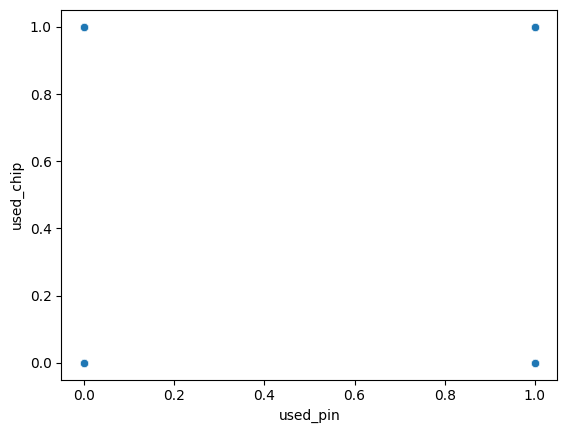

In [15]:
sns.scatterplot(x = df['used_pin'],y= df['used_chip'])
plt.show()

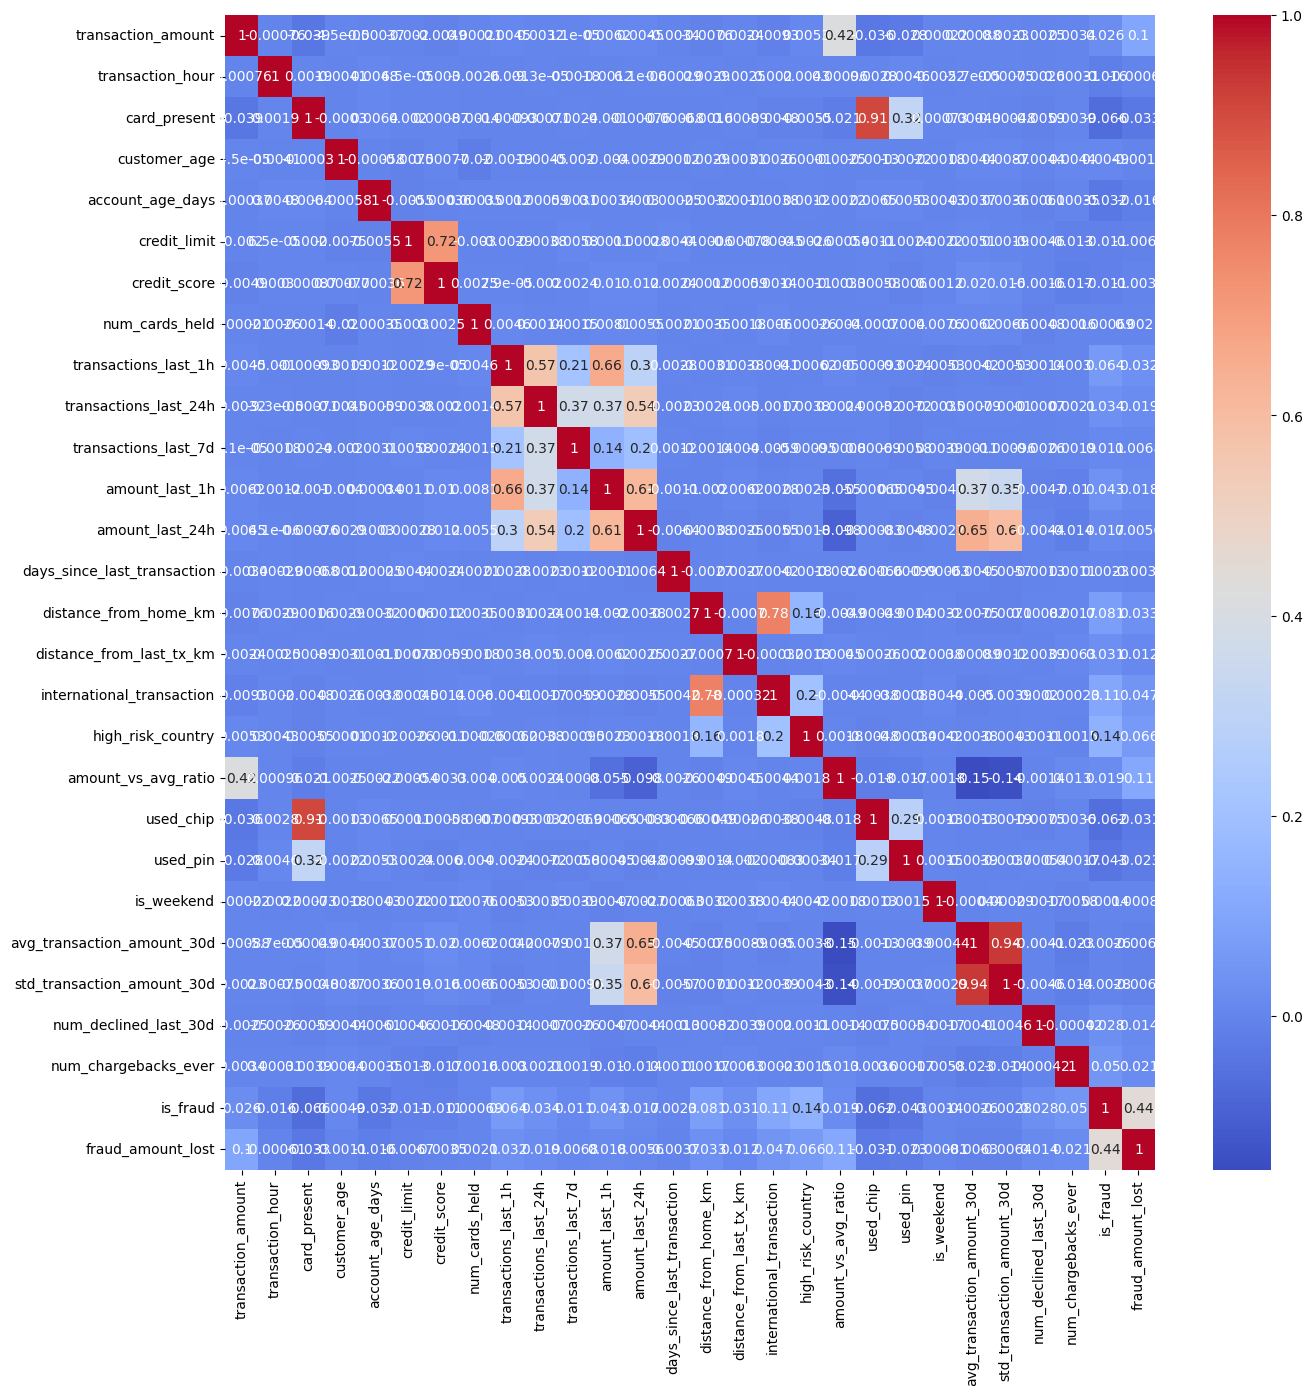

In [16]:
plt.figure(figsize=(15,15))
sns.heatmap(df.select_dtypes(include='number').drop(columns = 'transaction_id',errors ='ignore').corr(), annot=True,cmap =  'coolwarm')
plt.show()


In [17]:
df.select_dtypes(include ='object').columns

Index(['transaction_id', 'customer_id', 'card_id', 'merchant_id',
       'transaction_datetime', 'merchant_category', 'merchant_country',
       'transaction_day_of_week', 'customer_gender', 'customer_state',
       'transaction_channel', 'device_type', 'browser', 'email_domain',
       'fraud_type'],
      dtype='object')

In [19]:
print(df['fraud_type'].value_counts(dropna = False))

fraud_type
Legitimate            97945
Card-Not-Present       1054
Account-Takeover        447
Synthetic-Identity      309
Card-Present            245
Name: count, dtype: int64


In [20]:
print(df['used_chip'].value_counts(dropna = False))

used_chip
0    68521
1    31479
Name: count, dtype: int64


In [21]:
print(df['used_pin'].value_counts(dropna = False))

used_pin
0    81613
1    18387
Name: count, dtype: int64


In [22]:
df.columns = df.columns.str.strip()
for  col in df.select_dtypes(include ='object').columns:
     df[col] = df[col].str.strip()

In [24]:
df['fraud_type'] = df['fraud_type'].map({'included': 1, 'Not included': 0})
df['used_pin'] = df['used_pin'].map({'Yes': 1, 'No': 0})
df['used_chip'] = df['used_chip'].map({'Yes': 1, 'No': 0})

In [25]:
# Divide the dataset into X, & Y
X = df.drop(columns=['used_pin','used_chip'])
Y = df['used_chip']

In [26]:
# Train_Test
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)


In [29]:
# Model
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
model.fit(X_train,Y_train)

RandomForestClassifier()

In [30]:
y_pred = model.predict(X_test)

In [31]:
print(y_pred[:10])

[0 0 0 0 0 0 0 0 0 0]


In [32]:
result = pd.DataFrame({'Actual':Y_test,'Predicted':y_pred})
result.head(10)

,Actual,Predicted
75721,0,0
80184,0,0
19864,0,0
76699,0,0
92991,0,0
76434,0,0
84004,0,0
80917,0,0
60767,0,0
50074,0,0


In [33]:
from sklearn.metrics import accuracy_score
accuracy_score(Y_test,y_pred)


0.9797

In [34]:
train_accuray = model.score(X_train,Y_train)
test_accuracy = model.score(X_test,Y_test)
print(train_accuray,test_accuracy)

0.9999375 0.9797


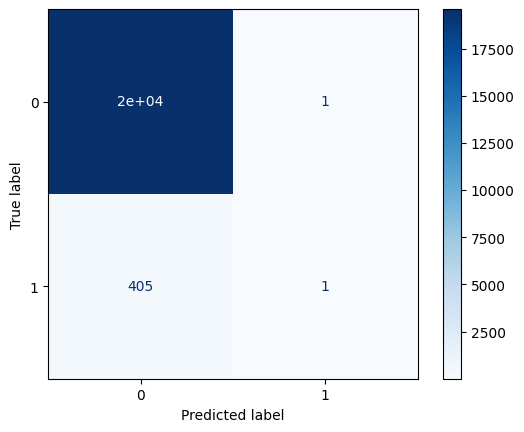

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute the confusion matrix first
cm = confusion_matrix(Y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap='Blues')
plt.show()

In [37]:
from sklearn.metrics import classification_report
print(classification_report(Y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99     19594
           1       0.50      0.00      0.00       406

    accuracy                           0.98     20000
   macro avg       0.74      0.50      0.50     20000
weighted avg       0.97      0.98      0.97     20000



In [ ]:
# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100,50, 150, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(),
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, Y_train)



Fitting 5 folds for each of 144 candidates, totalling 720 fits


In [ ]:
print(grid.best_params_)
print(grid.best_score_)


In [ ]:
best_model = grid.best_estimator_

print("Training Accuracy:", best_model.score(X_train, Y_train))
print("Testing Accuracy:", best_model.score(X_test, Y_test))

In [ ]:
print("Before Tuning:", model.score(X_test, Y_test))
print("After Tuning:", best_model.score(X_test, Y_test))